# Stage 5: Player xPTS and shot making

Research question RQ2: which players score more points than the quality of their shots implies, and how much of it
is skill and how much is luck?

For every shot the main model of Stage 4 (`gbm_w2_ctx`, LightGBM + context) gives the probability p that an
**average** NBA player makes it in that situation (the shooter's identity is not a feature). With shot value v (2 or 3):

- xPTS = v · p, the expected points of the shot,
- r = v · (y − p), the residual (points above expectation),
- **shot making SM = (PTS − xPTS) / n**, the mean residual of a player's n shots (points per shot above an average
  shooter).

Rules carried over from Stage 4:
- only **out-of-sample** predictions (walk-forward test seasons 2015-16 to 2024-25), so a shot never influenced its
  own p; the hold-out season 2025-26 is used once at the end (section 9);
- SM is **centred per season**: the model's season bias (−1.2 to +1.6 p.p. of FG%) is a league-level drift, not a
  player's skill;
- heaves (`is_heave`, 0.4% of shots) are removed: they are almost never made and say nothing about shooting skill.

Method template: Daly-Grafstein & Bornn (2019) (residual-based FG% + beta-binomial shrinkage, evaluated by predicting
the second half of a season from the first half).

## 0. Setup

In [1]:
%load_ext autoreload
# re-import src/xpts after every change, no kernel restart needed
%autoreload 2

from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy import stats

from xpts.players import (add_season_halves, cluster_bootstrap, fit_prior, load_player_shots, player_table,
                          prior_designs, shrink)

FIG_DIR = Path("../reports/figures")
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})

shots = load_player_shots("../data/processed/oos_predictions.parquet", "../data/processed/shots_features.parquet",
                          "../data/raw/players/positions.parquet")
SEASONS = sorted(shots["SEASON"].unique())
print(f"{len(shots):,} shots, {shots['PLAYER_ID'].nunique():,} players, seasons {SEASONS[0]} to {SEASONS[-1]}")
print(f"players without a position: {shots['POS'].isna().sum()} shots")

2,091,980 shots, 1,441 players, seasons 2015-16 to 2024-25
players without a position: 0 shots


## 1. xPTS and the season centring

`load_player_shots` joins the out-of-sample predictions with the shot data (player, date, shot value) and computes
p, xPTS, r and its variance v²·p·(1 − p). Under the null "this player is an average shooter" r has mean 0 and this
variance, which gives every player's SM a known sampling variance s² = Σ v²p(1 − p) / n².

Below: league points and xPTS per shot in each season. The difference is the model's season bias, which the centred
residual `r_c` removes.

In [2]:
league = shots.groupby("SEASON").agg(shots=("r", "size"), pts=("pts", "mean"), xpts=("xpts", "mean"),
                                     fg=("y", "mean"), p=("p", "mean"))
league["diff"] = league["pts"] - league["xpts"]
display(league.round(4))
print(f"per-shot sd of r: {shots['r'].std():.3f} points (2PT {shots.loc[shots.is_three == 0, 'r'].std():.3f}, "
      f"3PT {shots.loc[shots.is_three == 1, 'r'].std():.3f})")

,shots,pts,xpts,fg,p,diff
SEASON,,,,,,
2015-16,207078,1.0082,1.0308,0.4537,0.4648,-0.0226
2016-17,209039,1.0309,1.0375,0.4590,0.4627,-0.0066
2017-18,210775,1.0464,1.0349,0.4621,0.4561,0.0114
2018-19,218600,1.0518,1.0750,0.4621,0.4713,-0.0232
2019-20,187385,1.0611,1.0618,0.4617,0.4613,-0.0006
2020-21,190331,1.0789,1.0457,0.4675,0.4526,0.0332
2021-22,215899,1.0667,1.0614,0.4626,0.4579,0.0053
2022-23,216395,1.0937,1.0749,0.4769,0.4674,0.0188
2023-24,217895,1.0965,1.0803,0.4759,0.4694,0.0162


per-shot sd of r: 1.150 points (2PT 0.945, 3PT 1.439)


**Observations.**
- 2,091,980 shots of 1,441 players; every player has a listed position.
- League points minus xPTS per season range from −0.023 (2018-19) to +0.033 points per shot (2020-21). This is the
  season bias of Stage 4 on the points scale; without centring, every player of 2020-21 would get a bonus of 0.03.
- One shot is very noisy: sd of r is 1.15 points (3PT 1.44). A player needs hundreds of shots before his mean residual
  says much, which is why shrinkage is needed.

## 2. Raw shot making: signal or noise?

A funnel plot: raw SM of every player-season against the number of shots. The dashed lines are ±1.96 standard errors of
an average shooter (s = σ / √n with σ² the league mean of v²p(1 − p)). If SM were pure luck, 95% of the points would lie
inside the funnel.

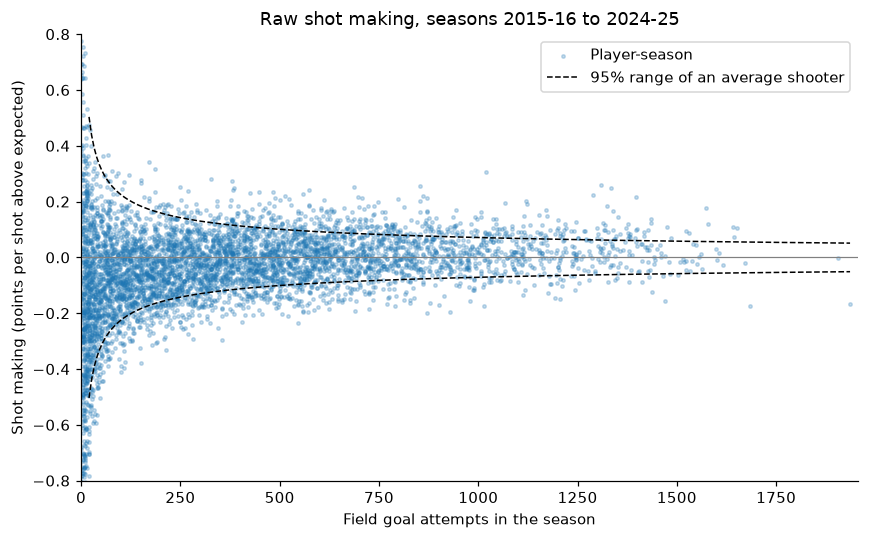

n >= 100:  3936 player-seasons, outside the funnel 23.9% (5% expected), sd(z) = 1.72 (1 expected)
n >= 300:  2667 player-seasons, outside the funnel 27.5% (5% expected), sd(z) = 1.85 (1 expected)
n >= 600:  1322 player-seasons, outside the funnel 33.2% (5% expected), sd(z) = 2.01 (1 expected)


In [3]:
t = player_table(shots)
sigma2 = shots["var"].mean()
t["z"] = t["sm"] / np.sqrt(t["s2"])

fig, ax = plt.subplots(figsize=(8, 5))
ax.scatter(t["n"], t["sm"], s=5, alpha=0.25, color="tab:blue", label="Player-season")
nn = np.linspace(20, t["n"].max(), 300)
for sgn in (-1, 1):
    ax.plot(nn, sgn * 1.96 * np.sqrt(sigma2 / nn), color="black", ls="--", lw=1,
            label="95% range of an average shooter" if sgn == 1 else None)
ax.axhline(0, color="grey", lw=0.8)
ax.set(xlabel="Field goal attempts in the season", ylabel="Shot making (points per shot above expected)",
       ylim=(-0.8, 0.8), xlim=(0, t["n"].max() + 20), title="Raw shot making, seasons 2015-16 to 2024-25")
ax.legend(loc="upper right")
fig.tight_layout()
fig.savefig(FIG_DIR / "05_funnel.pdf")
plt.show()

for n_min in [100, 300, 600]:
    big = t[t["n"] >= n_min]
    print(f"n >= {n_min}: {len(big):5d} player-seasons, outside the funnel {(big['z'].abs() > 1.96).mean():.1%} "
          f"(5% expected), sd(z) = {big['z'].std():.2f} (1 expected)")

**Observations.**
- The spread of raw SM is much wider than luck alone allows: 27.5% of player-seasons with ≥ 300 shots lie outside the
  95% funnel (5% expected) and the sd of the z-score is 1.85 instead of 1. **Shot making exists**: players differ
  in finishing the same shots.
- The excess grows with n (sd(z) 1.72 → 2.01), as expected if part of SM is a stable skill: noise shrinks with n, skill
  does not.
- Below about 100 shots the funnel is wide (±0.4 points per shot), so raw SM of small samples is mostly luck.

## 3. How reliable is shot making?

**Split-half reliability.** The shots of each player-season are numbered in time order and split into odd and even
shots. If SM measured only luck, the two halves would be uncorrelated. The correlation r of the halves is the
reliability of a half; the Spearman-Brown formula 2r / (1 + r) gives the reliability of the full season.

**Empirical Bayes.** `fit_prior` fits SM_i ~ N(μ, τ² + s_i²) by maximum likelihood: τ is the sd of *true* shot making
between players, and k = σ² / τ² is the number of shots at which an observed SM is half signal, half noise
(reliability n / (n + k)).

In [4]:
s = shots.sort_values(["GAME_DATE", "GAME_ID", "GAME_EVENT_ID"])
s["odd"] = s.groupby(["SEASON", "PLAYER_ID"]).cumcount() % 2
halves = s.groupby(["SEASON", "PLAYER_ID", "odd"])["r_c"].mean().unstack()
n_ps = s.groupby(["SEASON", "PLAYER_ID"]).size()

rel = []
for n_min in [100, 200, 300, 400, 600, 800]:
    h = halves[n_ps >= n_min]
    r = h.corr().iloc[0, 1]
    lo, hi = np.tanh(np.arctanh(r) + np.array([-1.96, 1.96]) / np.sqrt(len(h) - 3))  # Fisher z CI
    rel.append({"min shots": n_min, "player-seasons": len(h), "median n": int(n_ps[n_ps >= n_min].median()),
                "r halves": r, "ci_low": lo, "ci_high": hi, "Spearman-Brown": 2 * r / (1 + r)})
rel = pd.DataFrame(rel)
display(rel.round(3))

eb = []
for season, g in t.groupby("SEASON"):
    f = fit_prior(g["sm"], g["s2"])
    s2_league = shots.loc[shots["SEASON"] == season, "var"].mean()
    eb.append({"SEASON": season, "mu": f["beta"][0], "tau": np.sqrt(f["tau2"]), "k": s2_league / f["tau2"]})
eb = pd.DataFrame(eb).set_index("SEASON")
display(eb.round(4))
f_all = fit_prior(t["sm"], t["s2"])
K = sigma2 / f_all["tau2"]
print(f"all seasons: mu = {f_all['beta'][0]:.4f}, tau = {np.sqrt(f_all['tau2']):.4f} points/shot, k = {K:.0f} shots")

,min shots,player-seasons,median n,r halves,ci_low,ci_high,Spearman-Brown
0,100,3936,441,0.415,0.389,0.441,0.587
1,200,3250,524,0.458,0.431,0.485,0.629
2,300,2667,595,0.501,0.472,0.528,0.667
3,400,2167,677,0.537,0.506,0.566,0.699
4,600,1322,843,0.589,0.552,0.623,0.741
5,800,755,1024,0.600,0.552,0.644,0.750


,mu,tau,k
SEASON,,,
2015-16,-0.0064,0.0682,259.9850
2016-17,-0.0105,0.0693,259.5229
2017-18,-0.0076,0.0779,214.9053
2018-19,-0.0088,0.0632,330.4433
2019-20,-0.0107,0.0672,295.4548
2020-21,-0.0184,0.0807,206.4496
2021-22,-0.0134,0.0695,282.1152
2022-23,-0.0113,0.0729,253.4925
2023-24,-0.0181,0.0709,268.1795


all seasons: mu = -0.0121, tau = 0.0714 points/shot, k = 259 shots


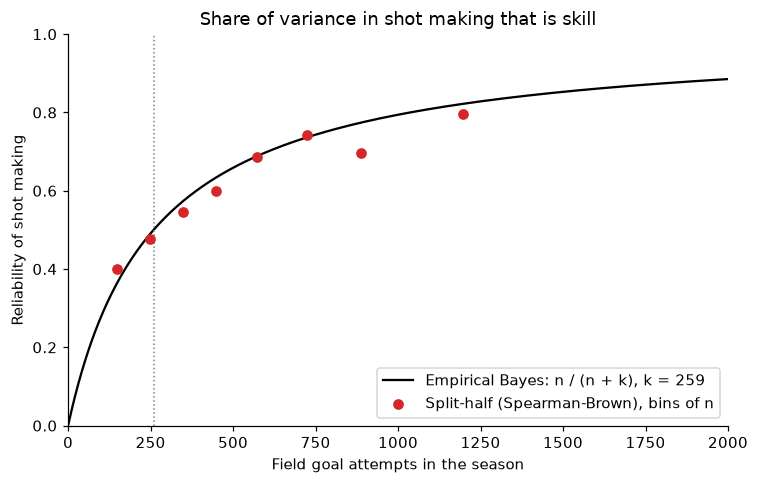

,n,rel,count
0,147.0,0.401,686
1,247.0,0.477,587
2,348.0,0.546,495
3,449.0,0.600,453
4,572.0,0.686,566
5,723.5,0.744,392
6,888.0,0.696,343
7,1195.5,0.796,410


In [5]:
# empirical reliability (odd/even, Spearman-Brown) in bins of n against the model curve n / (n + k)
bins = [100, 200, 300, 400, 500, 650, 800, 1000, 2000]
cut = pd.cut(n_ps, bins)
emp = []
for b, idx in halves.groupby(cut.reindex(halves.index), observed=True).groups.items():
    h = halves.loc[idx]
    r = h.corr().iloc[0, 1]
    emp.append({"n": n_ps.loc[idx].median(), "rel": 2 * r / (1 + r), "count": len(h)})
emp = pd.DataFrame(emp)

fig, ax = plt.subplots(figsize=(7, 4.5))
nn = np.linspace(1, 2000, 400)
ax.plot(nn, nn / (nn + K), color="black", label=f"Empirical Bayes: n / (n + k), k = {K:.0f}")
ax.scatter(emp["n"], emp["rel"], color="tab:red", zorder=3, label="Split-half (Spearman-Brown), bins of n")
ax.axvline(K, color="grey", ls=":", lw=1)
ax.set(xlabel="Field goal attempts in the season", ylabel="Reliability of shot making", ylim=(0, 1), xlim=(0, 2000),
       title="Share of variance in shot making that is skill")
ax.legend(loc="lower right")
fig.tight_layout()
fig.savefig(FIG_DIR / "05_reliability.pdf")
plt.show()
display(emp.round(3))

In [6]:
# year-to-year stability: raw SM in season S against S+1 (both seasons with at least 300 shots)
wide = t.pivot(index="PLAYER_ID", columns="SEASON", values="sm")
nw = t.pivot(index="PLAYER_ID", columns="SEASON", values="n")
pairs = pd.concat([pd.DataFrame({"a": wide[a], "b": wide[b], "na": nw[a], "nb": nw[b]})
                   for a, b in zip(SEASONS[:-1], SEASONS[1:])]).dropna()
pairs = pairs[(pairs["na"] >= 300) & (pairs["nb"] >= 300)]
r_yy = pairs[["a", "b"]].corr().iloc[0, 1]
print(f"year-to-year correlation of raw SM: r = {r_yy:.3f} ({len(pairs)} pairs, median n {pairs['na'].median():.0f})")

year-to-year correlation of raw SM: r = 0.577 (1820 pairs, median n 676)


**Observations.**
- Split-half reliability of SM over a season: 0.59 (≥ 100 shots) to 0.75 (≥ 800 shots); the correlation of the two
  halves is 0.42-0.60 with narrow Fisher-z CIs. About **half to three quarters of the variance of a full-season SM is
  skill**, the rest is luck.
- Empirical Bayes: the sd of true shot making between players is **τ ≈ 0.071 points per shot** (0.063-0.081 by season)
  and **k ≈ 260 shots** (206-330): a player with 260 shots has an SM that is half skill, half noise. The model curve
  n / (n + k) agrees with the empirical split-half reliability in bins of n (figure), so the normal-normal model fits.
- The prior mean μ is about −0.012: the league mean is a shot-weighted average (centring), and players with few shots
  shoot worse than those with many (section 8), so the *average player* is slightly below the *average shot*.
- Year-to-year correlation of raw SM (≥ 300 shots in both seasons): 0.58. Shot making is a persistent trait, comparable
  to the split-half reliability within a season.

## 4. Which prior? Position test on full seasons

Prior variants for the mean m_i of true shot making (`prior_designs`):

| Variant | Prior mean |
|---|---|
| league | one mean for all players |
| position | one mean per primary position (G, F, C; NBA.com listing) |
| previous | a + b · θ̂ of the previous season (players without one get their own mean) |
| pos_previous | position means + b · θ̂ of the previous season |

τ² is fitted for each variant, so a better prior mean also means a smaller τ² (less to learn from the player's own
shots). The position prior is nested in the league prior, so a **likelihood ratio test** (2 degrees of freedom) tells
whether the positions really differ.

In [7]:
theta_prev = {}   # shrunk SM per season with the league prior, used as the "previous season" input
lr = []
for i, season in enumerate(SEASONS):
    g = t[t["SEASON"] == season].copy()
    g["POS"] = g["PLAYER_ID"].map(shots.groupby("PLAYER_ID")["POS"].first())
    f0 = fit_prior(g["sm"], g["s2"])
    theta_prev[season] = pd.Series(shrink(g["sm"], g["s2"], f0["beta"][0], f0["tau2"])[0], index=g["PLAYER_ID"])
    prev = theta_prev[SEASONS[i - 1]] if i > 0 else None
    fits = {k: fit_prior(g["sm"], g["s2"], X) for k, X in prior_designs(g, prev).items()}
    row = {"SEASON": season, "tau_league": np.sqrt(fits["league"]["tau2"]),
           "tau_position": np.sqrt(fits["position"]["tau2"])}
    row.update({f"mu_{p}": b for p, b in zip("GFC", fits["position"]["beta"])})
    row["LR_position"] = 2 * (fits["position"]["loglik"] - fits["league"]["loglik"])
    row["p_position"] = stats.chi2.sf(row["LR_position"], 2)
    if prev is not None:
        row["b_previous"] = fits["previous"]["beta"][2]
        row["tau_previous"] = np.sqrt(fits["previous"]["tau2"])
        row["LR_previous"] = 2 * (fits["previous"]["loglik"] - fits["league"]["loglik"])
    lr.append(row)
lr = pd.DataFrame(lr).set_index("SEASON")
display(lr.round(4))
print(f"position effect significant at 5% in {(lr['p_position'] < 0.05).sum()} of {len(lr)} seasons")

,tau_league,tau_position,mu_G,mu_F,mu_C,LR_position,p_position,b_previous,tau_previous,LR_previous
SEASON,,,,,,,,,,
2015-16,0.0682,0.0649,-0.0243,-0.0031,0.0325,22.2024,0.0000,NaN,NaN,NaN
2016-17,0.0693,0.0649,-0.0294,-0.0056,0.0339,26.2844,0.0000,0.8817,0.0444,169.5710
2017-18,0.0779,0.0671,-0.0447,0.0166,0.0576,74.6235,0.0000,0.8679,0.0574,143.0301
2018-19,0.0632,0.0594,-0.0271,-0.0031,0.0382,30.8268,0.0000,0.7316,0.0430,160.5759
2019-20,0.0672,0.0656,-0.0216,-0.0091,0.0239,11.8652,0.0027,0.8548,0.0500,120.3680
2020-21,0.0807,0.0807,-0.0180,-0.0220,-0.0102,0.6113,0.7366,0.9560,0.0633,117.7372
2021-22,0.0695,0.0676,-0.0215,-0.0170,0.0290,15.2857,0.0005,0.7341,0.0488,149.3061
2022-23,0.0729,0.0719,-0.0156,-0.0160,0.0199,7.2726,0.0263,0.8779,0.0561,133.1795
2023-24,0.0709,0.0706,-0.0166,-0.0253,-0.0006,3.1835,0.2036,0.8500,0.0459,168.6003


position effect significant at 5% in 7 of 10 seasons


**Observations.**
- **Position:** the likelihood ratio test rejects a common mean in 7 of 10 seasons (p < 0.05), but the effect fades:
  in 2015-16 to 2018-19 centres were +0.03 to +0.06 and guards −0.02 to −0.04 points per shot above expected
  (LR 22-75), in 2020-21, 2023-24 and 2024-25 the test is not significant. The position prior reduces τ only from
  0.071 to 0.069 on average.
- **Previous season:** a much stronger prior. The slope b on last season's shrunk SM is 0.73-0.96 (close to 1:
  shrunk estimates are already "calibrated"), τ falls from about 0.071 to 0.051 and the likelihood gains 118-190
  points (LR) every season.
- The fading position effect is consistent with the label change of Stage 3/4: the model underrates layups (+1.7 p.p. over all
  seasons, mostly 2017-18 and 2018-19), shots taken mostly by centres. Section 8 checks this.

## 5. Main test: predict the second half of a season from the first half

As in Daly-Grafstein & Bornn (2019): every season is split at its median game date (`add_season_halves`). All
estimates use **only the first half** (the residuals are centred on the league mean of the first half, priors are
fitted on first-half SM, the "previous" variant uses the full previous season). The target is the observed SM in the
second half, scored by the mean squared error weighted by the second-half shots n₂ (a player with 500 shots weighs
more than one with 50).

The target is itself noisy; this noise adds the same constant to every method, so differences between methods are
fair. Uncertainty: bootstrap of whole **players** (all their seasons together), 1000 resamples. Seasons 2016-17 to
2024-25 (2015-16 has no previous out-of-sample season).

In [8]:
sh = add_season_halves(shots)
rows = []
for i, season in enumerate(SEASONS):
    a = player_table(sh[(sh["SEASON"] == season) & (sh["half"] == 1)], by=("PLAYER_ID",), resid="r_h")
    b = player_table(sh[(sh["SEASON"] == season) & (sh["half"] == 2)], by=("PLAYER_ID",), resid="r_h")
    a["POS"] = a["PLAYER_ID"].map(shots.groupby("PLAYER_ID")["POS"].first())
    prev = theta_prev[SEASONS[i - 1]] if i > 0 else None
    pred = pd.DataFrame({"PLAYER_ID": a["PLAYER_ID"], "n1": a["n"], "raw": a["sm"], "zero": 0.0})
    for k, X in prior_designs(a, prev).items():
        f = fit_prior(a["sm"], a["s2"], X)
        pred[k] = shrink(a["sm"], a["s2"], X @ f["beta"], f["tau2"])[0]
    pred = pred.merge(b[["PLAYER_ID", "n", "sm", "s2"]].rename(columns={"n": "n2", "sm": "sm2", "s2": "s2_2"}),
                      on="PLAYER_ID")
    pred["SEASON"] = season
    rows.append(pred)
half = pd.concat(rows, ignore_index=True)
half = half[half["SEASON"] != SEASONS[0]]
print(f"{len(half):,} player-seasons with shots in both halves")

METHODS = ["zero", "raw", "league", "position", "previous", "pos_previous"]
for m in METHODS:
    half[f"se_{m}"] = (half[m] - half["sm2"]) ** 2
res = {}
for label, q in {"all players": half, "n1 >= 100 and n2 >= 100": half[(half["n1"] >= 100) & (half["n2"] >= 100)]}.items():
    r = cluster_bootstrap(q, [f"se_{m}" for m in METHODS], weight="n2", base="se_league")
    r.index = METHODS
    # noise of the target: weighted mean of s2_2 (expected squared error of a perfect predictor)
    r["loss_minus_noise"] = r["loss"] - np.average(q["s2_2"], weights=q["n2"])
    res[label] = r
    print(f"{label}: {len(q):,} player-seasons")
    display((r * 1000).round(3).rename(columns=lambda c: c + " (x1000)"))

4,174 player-seasons with shots in both halves
all players: 4,174 player-seasons


,loss (x1000),diff (x1000),ci_low (x1000),ci_high (x1000),loss_minus_noise (x1000)
zero,10.861,2.492,1.919,3.206,4.846
raw,18.570,10.201,8.527,12.227,12.555
league,8.369,0.000,0.000,0.000,2.354
position,8.294,-0.075,-0.137,-0.013,2.279
previous,7.651,-0.718,-0.906,-0.533,1.636
pos_previous,7.632,-0.738,-0.928,-0.542,1.616


n1 >= 100 and n2 >= 100: 2,434 player-seasons


,loss (x1000),diff (x1000),ci_low (x1000),ci_high (x1000),loss_minus_noise (x1000)
zero,8.539,2.594,1.950,3.419,4.422
raw,7.950,2.005,1.622,2.387,3.834
league,5.945,0.000,0.000,0.000,1.829
position,5.927,-0.019,-0.086,0.048,1.810
previous,5.375,-0.571,-0.762,-0.393,1.258
pos_previous,5.391,-0.554,-0.758,-0.374,1.274


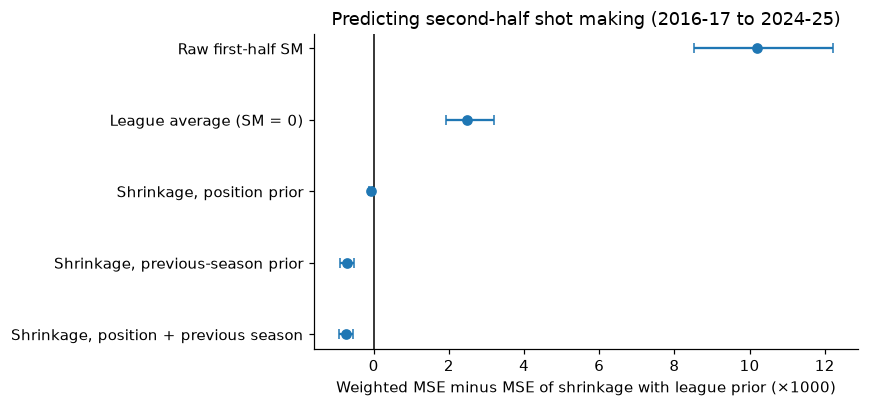

In [9]:
# figure: error relative to the league prior with 95% CI (all players)
r = res["all players"].drop(index="league")
names = {"zero": "League average (SM = 0)", "raw": "Raw first-half SM", "position": "Shrinkage, position prior",
         "previous": "Shrinkage, previous-season prior", "pos_previous": "Shrinkage, position + previous season"}
r = r.loc[["raw", "zero", "position", "previous", "pos_previous"]]
fig, ax = plt.subplots(figsize=(8, 3.8))
yy = np.arange(len(r))
ax.errorbar(1000 * r["diff"], yy, xerr=1000 * np.abs(r[["ci_low", "ci_high"]].to_numpy().T - r["diff"].to_numpy()),
            fmt="o", color="tab:blue", capsize=3)
ax.axvline(0, color="black", lw=1)
ax.set_yticks(yy, [names[m] for m in r.index])
ax.set(xlabel="Weighted MSE minus MSE of shrinkage with league prior (×1000)",
       title="Predicting second-half shot making (2016-17 to 2024-25)")
ax.invert_yaxis()
fig.tight_layout()
fig.savefig(FIG_DIR / "05_half_season_test.pdf")
plt.show()

In [10]:
# the same comparison season by season (all players), previous and position against league
by_season = half.groupby("SEASON").apply(lambda q: pd.Series({m: np.average(q[f"se_{m}"], weights=q["n2"]) for m in METHODS}),
                                        include_groups=False)
display((1000 * by_season.sub(by_season["league"], axis=0)).round(3))

,zero,raw,league,position,previous,pos_previous
SEASON,,,,,,
2016-17,2.680,6.877,0.0,-0.093,-0.685,-0.727
2017-18,3.154,6.123,0.0,-0.229,-0.585,-0.672
2018-19,2.099,7.815,0.0,-0.142,-0.730,-0.718
2019-20,1.780,8.041,0.0,-0.041,-0.552,-0.532
2020-21,2.748,9.414,0.0,0.006,-0.849,-0.849
2021-22,1.872,19.041,0.0,-0.123,-0.627,-0.736
2022-23,2.855,7.736,0.0,-0.018,-0.467,-0.442
2023-24,2.580,11.760,0.0,-0.022,-0.948,-0.937
2024-25,2.626,14.312,0.0,-0.003,-1.002,-1.007


**Observations.**
- **Raw first-half SM is the worst predictor**, even worse than predicting 0 for everybody (MSE +10.2·10⁻³ vs the league
  prior, CI [8.5; 12.2]). With n₁ ≥ 100 and n₂ ≥ 100 raw SM beats 0, but still loses to shrinkage by 2.0·10⁻³.
- **Shrinkage to the league prior** beats both: −7.7·10⁻³ vs raw and −2.5·10⁻³ vs "everyone average". This reproduces
  the main result of Daly-Grafstein & Bornn (2019) on 2015-2025 data and xPTS from a model with context.
- **Position prior: only a tiny gain**, −0.075·10⁻³ [−0.137; −0.013] for all players (1% of the league prior's error),
  zero for players with ≥ 100 shots in each half, and in recent seasons (2022-23 to 2024-25) practically zero. The
  split-half test does **not** justify position priors as the main variant.
- **Previous-season prior is clearly the best**: −0.72·10⁻³ [−0.91; −0.53] (≥ 100 shots: −0.57 [−0.76; −0.39]),
  better in every one of the nine seasons. Adding position to it changes nothing (−0.74 vs −0.72, CIs overlap).
- After subtracting the noise of the target (weighted mean s₂²), the error of the true second-half skill is 2.35·10⁻³
  for the league prior and 1.64·10⁻³ for the previous-season prior: the previous season removes 30% of the remaining
  error.
- **Decision: final estimates use the previous-season prior (`previous`).** Simpler than `pos_previous` and just as
  good.

## 6. Final shot making estimates

Full-season SM with the prior chosen in section 5 and 95% posterior intervals θ ± 1.96·√(w s²). Two views:
a single season (2024-25, at least 300 shots) and the whole period 2015-16 to 2024-25 pooled per player (the
residuals of all seasons, each centred on its season), shrunk to the league prior.

In [11]:
CHOSEN = "previous"   # chosen in section 5
est = []
for i, season in enumerate(SEASONS):
    g = t[t["SEASON"] == season].copy()
    g["POS"] = g["PLAYER_ID"].map(shots.groupby("PLAYER_ID")["POS"].first())
    designs = prior_designs(g, theta_prev[SEASONS[i - 1]] if i > 0 else None)
    X = designs.get(CHOSEN, designs["position"])
    f = fit_prior(g["sm"], g["s2"], X)
    g["prior"] = X @ f["beta"]
    g["theta"], g["post_var"] = shrink(g["sm"], g["s2"], g["prior"], f["tau2"])
    est.append(g)
est = pd.concat(est, ignore_index=True)
est["lo"] = est["theta"] - 1.96 * np.sqrt(est["post_var"])
est["hi"] = est["theta"] + 1.96 * np.sqrt(est["post_var"])
est["PLAYER_NAME"] = est["PLAYER_ID"].map(shots.groupby("PLAYER_ID")["PLAYER_NAME"].last())

cols = ["PLAYER_NAME", "POS", "n", "pts", "xpts", "sm", "prior", "theta", "lo", "hi"]
last = est[(est["SEASON"] == "2024-25") & (est["n"] >= 300)].sort_values("theta", ascending=False)
print("2024-25, best and worst shot makers (points per shot above expected)")
display(pd.concat([last.head(10), last.tail(5)])[cols].round(3))

2024-25, best and worst shot makers (points per shot above expected)


,PLAYER_NAME,POS,n,pts,xpts,sm,prior,theta,lo,hi
4865,Nikola Jokić,C,1335,1701,1374.240,0.249,0.176,0.228,0.178,0.277
4794,Kevin Durant,F,1123,1344,1131.454,0.193,0.112,0.165,0.111,0.219
5053,Payton Pritchard,G,853,1073,903.315,0.203,0.083,0.146,0.082,0.209
4897,Jakob Poeltl,C,578,727,648.786,0.139,0.088,0.118,0.058,0.177
4888,Domantas Sabonis,F,893,1119,996.052,0.141,0.070,0.116,0.061,0.171
4805,Stephen Curry,G,1246,1427,1273.392,0.127,0.095,0.115,0.059,0.172
4940,Grayson Allen,G,489,587,522.869,0.135,0.102,0.115,0.042,0.187
5112,Sam Hauser,F,473,594,518.308,0.164,0.087,0.114,0.040,0.188
4919,Luke Kennard,G,430,525,452.266,0.173,0.070,0.108,0.034,0.181
5035,Tyrese Haliburton,G,993,1170,1030.009,0.145,0.055,0.108,0.048,0.167


In [12]:
# whole period, pooled per player, league prior
career = player_table(shots, by=("PLAYER_ID",))
fc = fit_prior(career["sm"], career["s2"])
career["theta"], career["post_var"] = shrink(career["sm"], career["s2"], fc["beta"][0], fc["tau2"])
career["lo"] = career["theta"] - 1.96 * np.sqrt(career["post_var"])
career["hi"] = career["theta"] + 1.96 * np.sqrt(career["post_var"])
career["PLAYER_NAME"] = career["PLAYER_ID"].map(shots.groupby("PLAYER_ID")["PLAYER_NAME"].last())
career["POS"] = career["PLAYER_ID"].map(shots.groupby("PLAYER_ID")["POS"].first())
career["seasons"] = career["PLAYER_ID"].map(t.groupby("PLAYER_ID").size())
print(f"pooled: tau = {np.sqrt(fc['tau2']):.4f}, k = {sigma2 / fc['tau2']:.0f} shots, {len(career)} players")
big = career[career["n"] >= 3000].sort_values("theta", ascending=False)
print(f"players with >= 3000 shots: {len(big)}, interval above 0: {(big['lo'] > 0).sum()}, below 0: {(big['hi'] < 0).sum()}")
display(pd.concat([big.head(15), big.tail(5)])[["PLAYER_NAME", "POS", "seasons", "n", "pts", "xpts", "sm", "theta", "lo", "hi"]].round(3))

pooled: tau = 0.0707, k = 264 shots, 1441 players
players with >= 3000 shots: 232, interval above 0: 77, below 0: 48


,PLAYER_NAME,POS,seasons,n,pts,xpts,sm,theta,lo,hi
459,Nikola Jokić,C,10,11077,13271,10828.022,0.216,0.211,0.191,0.231
570,Jakob Poeltl,C,9,3720,4696,4075.661,0.159,0.150,0.120,0.180
172,Stephen Curry,G,10,11596,13852,12171.046,0.143,0.138,0.116,0.161
388,Seth Curry,G,9,4244,4956,4306.251,0.150,0.138,0.102,0.174
423,Joe Harris,G,9,3824,4681,4090.754,0.149,0.135,0.097,0.174
661,Luke Kennard,G,8,3496,4105,3576.233,0.145,0.131,0.090,0.171
107,Kevin Durant,F,9,10129,11881,10530.436,0.133,0.129,0.107,0.150
469,Joe Ingles,F,10,4145,4894,4377.278,0.123,0.111,0.073,0.149
95,JJ Redick,G,6,4551,5179,4661.249,0.121,0.111,0.076,0.146
362,Otto Porter Jr.,F,9,3880,4403,3982.463,0.112,0.103,0.067,0.139


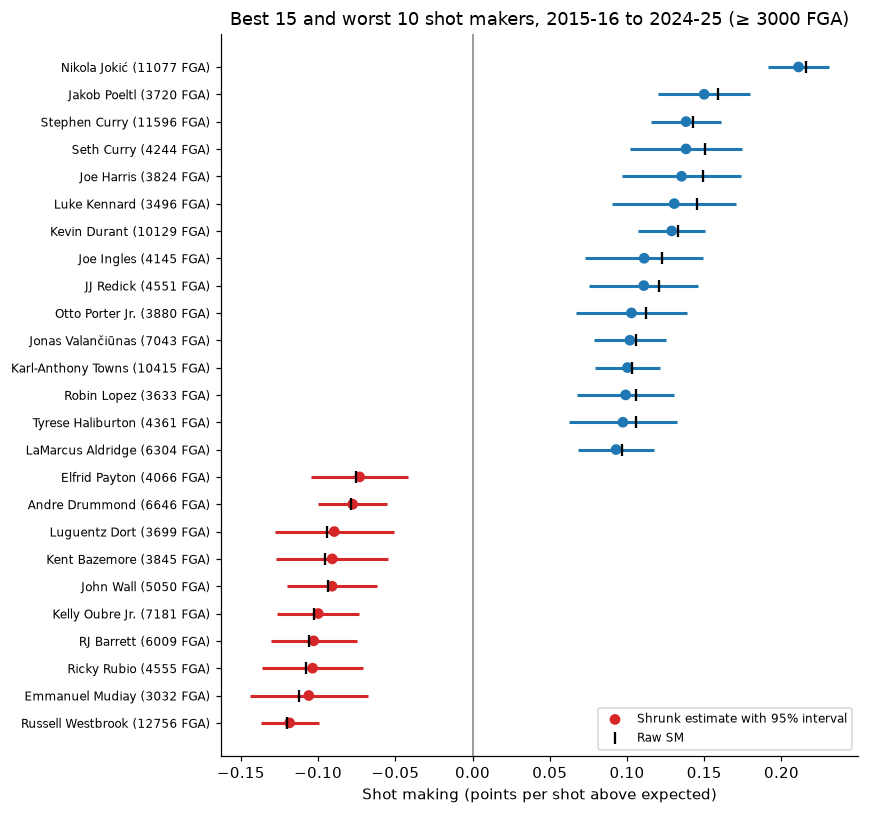

In [13]:
top = pd.concat([big.head(15), big.tail(10)]).sort_values("theta")
fig, ax = plt.subplots(figsize=(8, 7.5))
yy = np.arange(len(top))
col = np.where(top["theta"] > 0, "tab:blue", "tab:red")
ax.hlines(yy, top["lo"], top["hi"], color=col, lw=2)
ax.scatter(top["theta"], yy, color=col, zorder=3, label="Shrunk estimate with 95% interval")
ax.scatter(top["sm"], yy, color="black", marker="|", s=60, zorder=4, label="Raw SM")
ax.axvline(0, color="grey", lw=1)
ax.set_yticks(yy, [f"{n} ({int(s)} FGA)" for n, s in zip(top["PLAYER_NAME"], top["n"])], fontsize=8)
ax.set(xlabel="Shot making (points per shot above expected)",
       title="Best 15 and worst 10 shot makers, 2015-16 to 2024-25 (≥ 3000 FGA)")
ax.legend(loc="lower right", fontsize=8)
fig.tight_layout()
fig.savefig(FIG_DIR / "05_top_players.pdf")
plt.show()

In [14]:
# what does it mean in points? SM x shots per season for the top of 2024-25
last["points_added"] = last["theta"] * last["n"]
print("points per season above an average shooter on the same shots (shrunk), 2024-25:")
display(last.sort_values("points_added", ascending=False).head(10)[["PLAYER_NAME", "n", "theta", "points_added"]].round(2))

points per season above an average shooter on the same shots (shrunk), 2024-25:


,PLAYER_NAME,n,theta,points_added
4865,Nikola Jokić,1335,0.23,303.99
4794,Kevin Durant,1123,0.17,185.58
4951,Shai Gilgeous-Alexander,1652,0.09,154.30
4805,Stephen Curry,1246,0.12,143.75
5053,Payton Pritchard,853,0.15,124.17
4790,LeBron James,1266,0.09,112.60
5005,Tyler Herro,1373,0.08,110.10
5035,Tyrese Haliburton,993,0.11,107.01
4806,DeMar DeRozan,1299,0.08,106.14
4888,Domantas Sabonis,893,0.12,103.74


**Observations.**
- 2024-25: the best shot maker is **Nikola Jokić** (+0.23 points per shot, 95% interval [0.18; 0.28]: about 305 points
  in the season above an average player taking the same shots), then Kevin Durant (+0.17), Payton Pritchard, Jakob
  Poeltl, Domantas Sabonis and **Stephen Curry (+0.12)**. At the bottom are young players (Mogbo, Salaün, Coulibaly,
  Missi) and Clint Capela.
- Shrinkage pulls players with few shots strongly: Mogbo has raw −0.30 on 354 shots and ends at −0.18; Jokić with
  1335 shots moves only from 0.249 to 0.228.
- 2015-16 to 2024-25 pooled (232 players with ≥ 3000 shots): k = 264, **77 players have an interval fully above 0 and
  48 fully below 0**, so for about half of the regular shooters the sign of their shot making is clear after ten seasons.
- Top 5 of the decade: Jokić (+0.21 [0.19; 0.23]), Poeltl, Stephen Curry (+0.14), Seth Curry, Joe Harris; Durant 7th.
  Bottom: Russell Westbrook (−0.12 [−0.14; −0.10] on 12,756 shots: about 1,500 points below expectation), Mudiay,
  Rubio, Barrett, Oubre.
- Shooting specialists (Kennard, Redick, Ingles, Harris, Seth Curry) are near the top: the model knows the shot is a
  three from a given spot, but not who shoots it.

## 7. Case study: Stephen Curry

Curry is the usual example of a player whose shots look "bad" to a model (long, contested pull-up threes) but go in.
Below: his SM per season with the 95% interval, and the split into 2PT and 3PT shots.

In [15]:
CURRY = 201939
cs = est[est["PLAYER_ID"] == CURRY].set_index("SEASON")
display(cs[["n", "pts", "xpts", "sm", "prior", "theta", "lo", "hi"]].round(3))
cur = shots[shots["PLAYER_ID"] == CURRY]
by_type = cur.groupby(["SEASON", "is_three"]).agg(n=("y", "size"), fg=("y", "mean"), p=("p", "mean"), sm=("r_c", "mean")).unstack()
display(by_type.round(3))
c3 = cur[cur["is_three"] == 1]
print(f"Curry 3PT, all seasons: {len(c3)} shots, FG {c3['y'].mean():.3f}, expected {c3['p'].mean():.3f}, "
      f"league 3PT FG {shots.loc[shots.is_three == 1, 'y'].mean():.3f}")
print(f"career rank by shrunk SM among >= 3000 FGA: {int((big['theta'] > career.set_index('PLAYER_ID').loc[CURRY, 'theta']).sum()) + 1} of {len(big)}")

,n,pts,xpts,sm,prior,theta,lo,hi
SEASON,,,,,,,,
2015-16,1573,1979,1734.833,0.178,-0.024,0.140,0.084,0.195
2016-17,1416,1665,1545.884,0.091,0.132,0.105,0.053,0.157
2017-18,854,1065,917.579,0.161,0.072,0.129,0.061,0.197
2018-19,1323,1612,1400.187,0.183,0.090,0.146,0.093,0.199
2019-20,80,78,83.968,-0.074,0.121,0.099,0.007,0.192
2020-21,1339,1644,1375.238,0.168,-0.026,0.123,0.064,0.183
2021-22,1210,1343,1248.098,0.073,0.106,0.085,0.027,0.142
2022-23,1121,1385,1137.711,0.202,0.049,0.155,0.094,0.216
2023-24,1434,1654,1454.155,0.123,0.130,0.126,0.072,0.179


n          fg             p            sm       
is_three    0    1      0      1      0      1      0      1
SEASON                                                      
2015-16   712  861  0.566  0.454  0.504  0.394  0.147  0.203
2016-17   654  762  0.537  0.421  0.506  0.387  0.068  0.110
2017-18   363  491  0.595  0.430  0.482  0.386  0.215  0.121
2018-19   530  793  0.525  0.444  0.470  0.379  0.133  0.217
2019-20    33   47  0.636  0.255  0.495  0.364  0.283 -0.324
2020-21   564  775  0.569  0.431  0.462  0.367  0.182  0.157
2021-22   474  736  0.527  0.382  0.458  0.369  0.134  0.034
2022-23   494  627  0.579  0.432  0.463  0.362  0.214  0.192
2023-24   569  865  0.515  0.412  0.461  0.358  0.092  0.144
2024-25   474  772  0.534  0.398  0.472  0.357  0.128  0.126

Curry 3PT, all seasons: 6729 shots, FG 0.421, expected 0.373, league 3PT FG 0.363
career rank by shrunk SM among >= 3000 FGA: 3 of 232


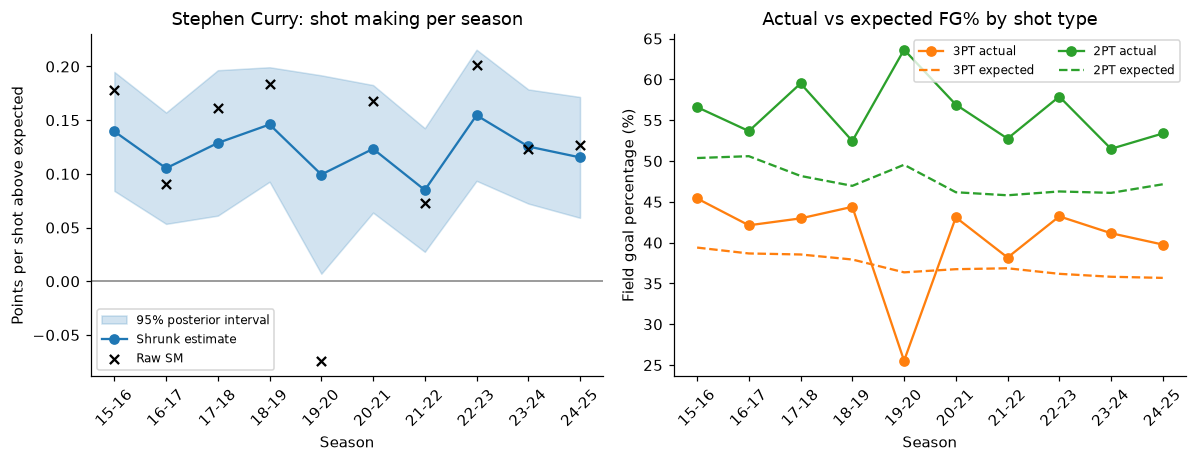

In [16]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.3))
x = np.arange(len(cs))
ax = axes[0]
ax.fill_between(x, cs["lo"], cs["hi"], color="tab:blue", alpha=0.2, label="95% posterior interval")
ax.plot(x, cs["theta"], marker="o", color="tab:blue", label="Shrunk estimate")
ax.scatter(x, cs["sm"], color="black", marker="x", label="Raw SM", zorder=3)
ax.axhline(0, color="grey", lw=1)
ax.set_xticks(x, [s[2:] for s in cs.index], rotation=45)
ax.set(xlabel="Season", ylabel="Points per shot above expected", title="Stephen Curry: shot making per season")
ax.legend(fontsize=8)
ax = axes[1]
for k, lab, c in [(1, "3PT", "tab:orange"), (0, "2PT", "tab:green")]:
    ax.plot(x, 100 * by_type[("fg", k)], marker="o", color=c, label=f"{lab} actual")
    ax.plot(x, 100 * by_type[("p", k)], ls="--", color=c, label=f"{lab} expected")
ax.set_xticks(x, [s[2:] for s in by_type.index], rotation=45)
ax.set(xlabel="Season", ylabel="Field goal percentage (%)", title="Actual vs expected FG% by shot type")
ax.legend(fontsize=8, ncol=2)
fig.tight_layout()
fig.savefig(FIG_DIR / "05_curry.pdf")
plt.show()

**Observations.**
- Curry's shrunk SM is positive in every season, between +0.08 and +0.15 points per shot; the 95% interval excludes 0
  in all ten seasons (barely in 2019-20). Over the decade he is 3rd of 232 high-volume players.
- On 3PT shots he makes 42.1% where the model expects 37.3% for an average player (league 3PT 36.3%): the model rates
  his threes as roughly average shots and he beats that by 4.8 p.p. on 6,729 attempts. On 2PT shots he is 3-12 p.p.
  above expectation every season.
- **2019-20 shows why shrinkage matters**: he played 5 games (80 shots) after a hand injury, raw SM −0.07. With the
  previous-season prior the estimate stays at +0.09 [0.00; 0.19]: 80 shots are too few to overturn five seasons of
  evidence. A raw ranking would have put him among the poor shooters that season.

## 8. Robustness and limits

1. Does SM depend on the xPTS model? SM computed with the logit + context (`logit_w1_ctx`) instead of LightGBM.
2. Is SM related to shot difficulty? Correlation of SM with the player's mean p. A strong negative relation would mean
   the model systematically underrates hard shots (part of "shot making" would be model error, e.g. the missing
   defender distance).
3. Is SM related to volume? Players who take many shots are selected by coaches for shooting well.

In [17]:
alt = load_player_shots("../data/processed/oos_predictions.parquet", "../data/processed/shots_features.parquet",
                        model="logit_w1_ctx")
t_alt = player_table(alt)
both = t.merge(t_alt[["SEASON", "PLAYER_ID", "sm"]], on=["SEASON", "PLAYER_ID"], suffixes=("", "_logit"))
q = both[both["n"] >= 300]
print(f"SM LightGBM vs logit, n >= 300: r = {q[['sm', 'sm_logit']].corr().iloc[0, 1]:.3f}, "
      f"mean |difference| {np.abs(q['sm'] - q['sm_logit']).mean():.4f} points/shot")

diff = shots.groupby(["SEASON", "PLAYER_ID"])["p"].mean().rename("mean_p").reset_index()
q = t.merge(diff, on=["SEASON", "PLAYER_ID"])
q = q[q["n"] >= 300]
rho = stats.spearmanr(q["mean_p"], q["sm"])
print(f"SM vs mean p (shot difficulty), n >= 300: Spearman rho = {rho.statistic:.3f}, p = {rho.pvalue:.2g}")
q["n_bin"] = pd.qcut(q["n"], 4)
display(q.groupby("n_bin", observed=True)["sm"].agg(["mean", "size"]).round(4))
q["POS"] = q["PLAYER_ID"].map(shots.groupby("PLAYER_ID")["POS"].first())
display(q.groupby("POS")[["sm", "mean_p"]].mean().round(4))

SM LightGBM vs logit, n >= 300: r = 0.995, mean |difference| 0.0060 points/shot
SM vs mean p (shot difficulty), n >= 300: Spearman rho = -0.175, p = 9.1e-20


,mean,size
n_bin,,
"(299.999, 435.0]",-0.0138,671
"(435.0, 595.0]",-0.0059,663
"(595.0, 841.0]",0.0100,669
"(841.0, 1936.0]",0.0214,664


,sm,mean_p
POS,,
C,0.0370,0.5305
F,0.0040,0.4692
G,-0.0066,0.4434


In [18]:
# 4. shot-type bias of the model: residuals centred per season AND shot type (action_group) instead of per season
#    (Stage 4: layups +1.7 p.p., pull-ups -2.2 p.p.); the ranking should not be driven by this bias
shots["r_t"] = shots["r"] - shots.groupby(["SEASON", "action_group"])["r"].transform("mean")
t_type = player_table(shots, resid="r_t")
q = t.merge(t_type[["SEASON", "PLAYER_ID", "sm"]], on=["SEASON", "PLAYER_ID"], suffixes=("", "_type"))
q = q[q["n"] >= 300]
q["POS"] = q["PLAYER_ID"].map(shots.groupby("PLAYER_ID")["POS"].first())
print(f"SM centred per season vs per season x shot type, n >= 300: r = {q[['sm', 'sm_type']].corr().iloc[0, 1]:.3f}")
display(q.groupby("POS")[["sm", "sm_type"]].mean().round(4))
c = player_table(shots, by=("PLAYER_ID",), resid="r_t").set_index("PLAYER_ID")
big_t = big.assign(sm_type=big["PLAYER_ID"].map(c["sm"]))
big_t["rank"] = big_t["sm"].rank(ascending=False).astype(int)
big_t["rank_type"] = big_t["sm_type"].rank(ascending=False).astype(int)
display(big_t.sort_values("rank").head(10)[["PLAYER_NAME", "POS", "n", "sm", "sm_type", "rank", "rank_type"]].round(3))

SM centred per season vs per season x shot type, n >= 300: r = 0.989


,sm,sm_type
POS,,
C,0.0370,0.0283
F,0.0040,0.0001
G,-0.0066,-0.0026


,PLAYER_NAME,POS,n,sm,sm_type,rank,rank_type
459,Nikola Jokić,C,11077,0.216,0.213,1,1
570,Jakob Poeltl,C,3720,0.159,0.149,2,4
388,Seth Curry,G,4244,0.150,0.162,3,2
423,Joe Harris,G,3824,0.149,0.143,4,7
661,Luke Kennard,G,3496,0.145,0.154,5,3
172,Stephen Curry,G,11596,0.143,0.148,6,5
107,Kevin Durant,F,10129,0.133,0.145,7,6
469,Joe Ingles,F,4145,0.123,0.121,8,9
95,JJ Redick,G,4551,0.121,0.136,9,8
362,Otto Porter Jr.,F,3880,0.112,0.120,10,10


**Observations.**
1. **The xPTS model hardly matters**: SM from the logit + context correlates 0.995 with SM from LightGBM (mean absolute
   difference 0.006 points per shot). Rankings are a property of the data, not of the model class.
2. **Weak relation to shot difficulty**: Spearman ρ = −0.18 between SM and mean p (p < 10⁻¹⁹). Players with harder
   shots have slightly higher SM. Possible reasons: hard-shot takers are selected for being good at them, or the model
   misses difficulty that good shooters overcome (no defender distance). It cannot be separated with these data.
3. **Volume**: mean SM rises from −0.014 (300-435 shots) to +0.021 (841+ shots). Coaches give more shots to players who
   make them, so volume carries information about skill; a prior with log n raised the likelihood in a prototype but
   did not improve the n₂-weighted test, so it was not pursued.
4. **Shot-type bias**: centring per season × shot type instead of per season changes little (r = 0.989); centres lose
   about a quarter of their advantage (+0.037 → +0.028), the decade top 10 stays the same set of players with small
   rank changes (Poeltl 2nd → 4th). Part of the centre/position effect of section 4 is the model's layup bias.

## 9. Hold-out season 2025-26 (run once)

Everything above was decided on 2015-16 to 2024-25. Here the same procedure is applied once to the hold-out season,
with the predictions of the main model from `09_holdout` (trained on 2023-24 and 2024-25):
1. the first-half → second-half test of section 5 (previous season = 2024-25);
2. predicting the full 2025-26 SM from the 2024-25 estimates alone (raw vs shrunk), the use case "who will shoot well
   next season".

In [19]:
hs = load_player_shots("../data/processed/holdout_predictions.parquet", "../data/processed/shots_features.parquet",
                       "../data/raw/players/positions.parquet")
print(f"2025-26: {len(hs):,} shots, {hs['PLAYER_ID'].nunique()} players, positions missing for "
      f"{hs['POS'].isna().sum()} shots")
hs["POS"] = hs["POS"].fillna("G")
hh = add_season_halves(hs)
a = player_table(hh[hh["half"] == 1], by=("PLAYER_ID",), resid="r_h")
b = player_table(hh[hh["half"] == 2], by=("PLAYER_ID",), resid="r_h")
a["POS"] = a["PLAYER_ID"].map(hs.groupby("PLAYER_ID")["POS"].first())
pred = pd.DataFrame({"PLAYER_ID": a["PLAYER_ID"], "n1": a["n"], "raw": a["sm"], "zero": 0.0})
for k, X in prior_designs(a, theta_prev["2024-25"]).items():
    f = fit_prior(a["sm"], a["s2"], X)
    pred[k] = shrink(a["sm"], a["s2"], X @ f["beta"], f["tau2"])[0]
pred = pred.merge(b[["PLAYER_ID", "n", "sm"]].rename(columns={"n": "n2", "sm": "sm2"}), on="PLAYER_ID")
for m in METHODS:
    pred[f"se_{m}"] = (pred[m] - pred["sm2"]) ** 2
r = cluster_bootstrap(pred, [f"se_{m}" for m in METHODS], weight="n2", base="se_league")
r.index = METHODS
print(f"first half -> second half, {len(pred)} players")
display((1000 * r).round(3))

2025-26: 218,901 shots, 582 players, positions missing for 0 shots
first half -> second half, 477 players


,loss,diff,ci_low,ci_high
zero,11.625,2.113,1.062,3.270
raw,20.430,10.919,5.769,18.710
league,9.511,0.000,0.000,0.000
position,9.692,0.180,0.046,0.326
previous,8.635,-0.877,-1.394,-0.398
pos_previous,8.780,-0.731,-1.256,-0.247


In [20]:
# 2024-25 estimates -> full 2025-26 SM
t_h = player_table(hs)
nxt = t_h.merge(est[est["SEASON"] == "2024-25"][["PLAYER_ID", "sm", "theta"]].rename(columns={"sm": "raw", "theta": "shrunk"}),
                on="PLAYER_ID")
nxt["zero"] = 0.0
for m in ["zero", "raw", "shrunk"]:
    nxt[f"se_{m}"] = (nxt[m] - nxt["sm"]) ** 2
r2 = cluster_bootstrap(nxt, ["se_zero", "se_raw", "se_shrunk"], weight="n", base="se_shrunk")
print(f"2024-25 -> 2025-26, {len(nxt)} players")
display((1000 * r2).round(3))
q = nxt[nxt["n"] >= 300]
print(f"correlation with 2025-26 SM (n >= 300): raw {q[['raw', 'sm']].corr().iloc[0, 1]:.3f}, "
      f"shrunk {q[['shrunk', 'sm']].corr().iloc[0, 1]:.3f}")

2024-25 -> 2025-26, 464 players


,loss,diff,ci_low,ci_high
se_zero,8.300,2.547,1.315,3.846
se_raw,10.701,4.947,3.264,7.006
se_shrunk,5.754,0.000,0.000,0.000


correlation with 2025-26 SM (n >= 300): raw 0.491, shrunk 0.566


**Observations.**
- **First half → second half on 2025-26** (477 players): the order is the same as in development. Raw SM is the worst
  (+10.9·10⁻³), shrinkage to the league prior beats predicting 0 (−2.1·10⁻³ [−3.3; −1.1]), and the previous-season
  prior is the best (−0.88·10⁻³ [−1.39; −0.40] vs league).
- **The position prior is worse than the league prior on the hold-out** (+0.18·10⁻³ [0.05; 0.33]), which confirms the
  decision not to use it.
- **2024-25 → 2025-26** (464 players): the shrunk 2024-25 estimate predicts next season's SM much better than raw SM
  (MSE −4.9·10⁻³ [−7.0; −3.3]) and than 0 (−2.5·10⁻³). Correlation with 2025-26 SM for players with ≥ 300 shots: raw
  0.49, shrunk 0.57.

## 10. Summary

- **Answer to RQ2.** Shot making SM = (PTS − xPTS)/n exists and is persistent: the spread between players is about
  twice the luck-only spread; τ ≈ 0.07 points per shot between true skills; a full season (≥ 300 shots) is about
  60-75% skill; the year-to-year correlation is 0.58. With k ≈ 260 shots, a season of fewer than 260 shots is mostly
  luck.
- **Shrinkage** is necessary: raw first-half SM predicts the second half worse than assuming everyone is average;
  empirical Bayes shrinkage beats both, on development seasons and on the hold-out.
- **Prior:** the previous season is the best prior (−0.72·10⁻³ MSE vs league, 30% less error on the true skill).
  **Positions** differed in 2015-2019 (centres above, guards below) but the effect faded, gives ≈ 1% gain in the
  split-half test and is worse on 2025-26, so position priors are **not justified**.
- **Players:** Jokić is the best shot maker of the decade (+0.21 points per shot), Stephen Curry 3rd (+0.14, positive
  in every season), Westbrook the worst among high-volume players (−0.12).
- **Limits:** no defender distance (part of SM is unobserved difficulty), a weak negative relation of SM to mean p,
  model shot-type bias (small effect on rankings), primary position is one per career.

Figures: `05_funnel.pdf`, `05_reliability.pdf`, `05_half_season_test.pdf`, `05_top_players.pdf`, `05_curry.pdf`.